In [ ]:
import pandas as pd
df = pd.read_csv('https://raw.githubusercontent.com/ganjar87/data_science_practice/main/BankChurners.csv', delimiter=',')
df.head()

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000


In [ ]:
df.tail()

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
10122,772366833,Existing Customer,50,M,2,Graduate,Single,$40K - $60K,Blue,40,...,2,3,4003.0,1851,2152.0,0.703,15476,117,0.857,0.462
10123,710638233,Attrited Customer,41,M,2,Unknown,Divorced,$40K - $60K,Blue,25,...,2,3,4277.0,2186,2091.0,0.804,8764,69,0.683,0.511
10124,716506083,Attrited Customer,44,F,1,High School,Married,Less than $40K,Blue,36,...,3,4,5409.0,0,5409.0,0.819,10291,60,0.818,0.000
10125,717406983,Attrited Customer,30,M,2,Graduate,Unknown,$40K - $60K,Blue,36,...,3,3,5281.0,0,5281.0,0.535,8395,62,0.722,0.000
10126,714337233,Attrited Customer,43,F,2,Graduate,Married,Less than $40K,Silver,25,...,2,4,10388.0,1961,8427.0,0.703,10294,61,0.649,0.189


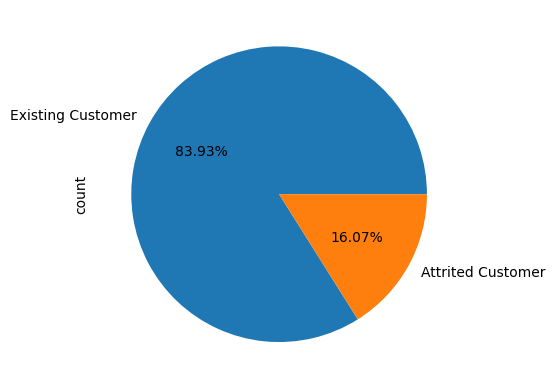

In [ ]:
import matplotlib.pyplot as plt

data = df['Attrition_Flag'].value_counts()
data.plot(kind='pie',autopct='%.2f%%')
plt.show()

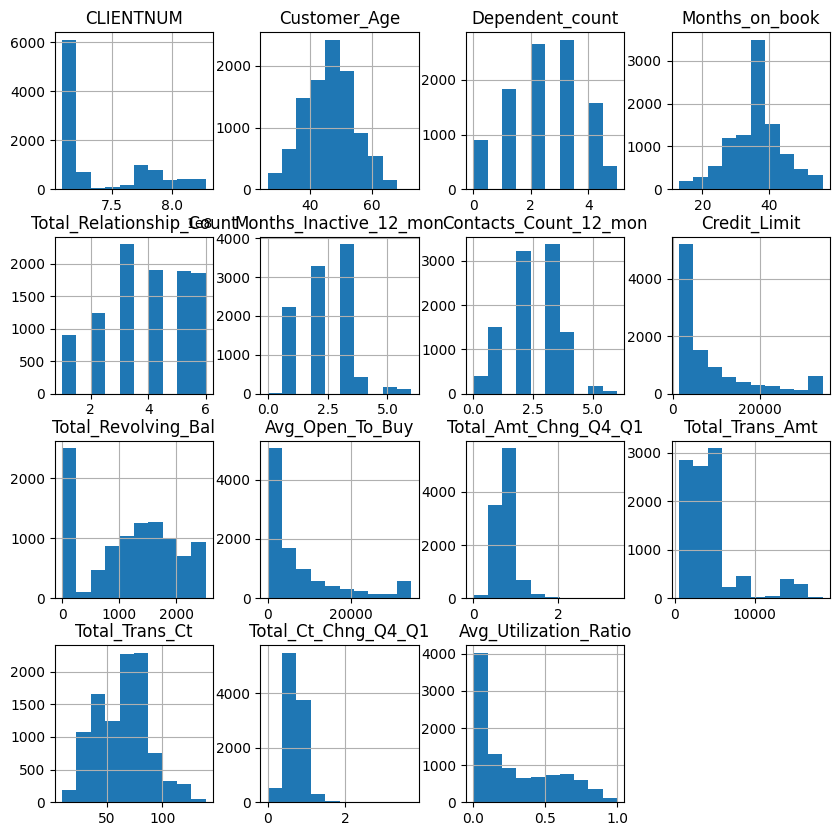

In [ ]:
df.hist(figsize=(10,10))
plt.show()

In [ ]:
df.isnull().sum()

,0
CLIENTNUM,0
Attrition_Flag,0
Customer_Age,0
Gender,0
Dependent_count,0
Education_Level,0
Marital_Status,0
Income_Category,0
Card_Category,0
Months_on_book,0


In [ ]:
df_X = df.drop(['CLIENTNUM', 'Attrition_Flag'],axis=1)
df_y = df[['Attrition_Flag']]
cats = df_X.select_dtypes(include=['object', 'bool']).columns
print(cats)

Index(['Gender', 'Education_Level', 'Marital_Status', 'Income_Category',
       'Card_Category'],
      dtype='object')


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from imblearn.metrics import sensitivity_specificity_support
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OrdinalEncoder
from sklearn.neural_network import MLPClassifier

# get X and y
df_X = df.drop(['CLIENTNUM',    'Attrition_Flag'],axis=1)
df_y = df[['Attrition_Flag']]

#label encoding for y.
#merubah nilai yg ada di y menjadi 0 atau 1.
#sebenarnya ini tidak diperlukan karena nilai y di dataset sudah 0 atau 1
le = LabelEncoder()
df_y= le.fit_transform(df_y['Attrition_Flag'])


#categorical encoding
#merubah categorical value menjadi numerical value
#bisa pakai label encoding, ordinal atau one hot encoding
cats = df_X.select_dtypes(include=['object', 'bool']).columns
cat_features = list(cats.values)
le = LabelEncoder()
for i in cat_features:
 le.fit(df_X[i])
 df_X[i] = le.transform(df_X[i])

#menyimpan X dan y menjadi numpy arrays
X = df_X.astype(float).values
y = df_y.astype(float)

#hold-out method, dibagi menjadi training dan testing set. 70% training, 30% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

#scaling
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

#mulai learning
model=MLPClassifier(max_iter=500)
#model=MLPClassifier(max_iter=1000, random_state=42, activation='logistic')
model.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


MLPClassifier(max_iter=500)

In [ ]:
model.coefs_

[array([[-0.64357894,  0.30366415, -0.20314144, ..., -0.02376194,
         -0.21557447, -0.05817603],
        [-0.15921403,  0.20250915, -0.06730662, ..., -0.03826105,
         -0.02400545, -0.04880542],
        [-0.20764559, -0.51607871,  0.07535142, ...,  0.6045253 ,
          0.02088415, -0.40286647],
        ...,
        [-0.59685165,  0.33874625,  1.38610939, ...,  0.30128946,
          0.09306806,  0.18024433],
        [ 0.06531778,  0.22598917, -0.98253375, ..., -0.02050833,
         -0.14078931,  0.2352378 ],
        [-0.13572945,  0.55820145,  0.20361945, ...,  0.10626988,
         -0.09071913, -0.31144966]]),
 array([[-0.64015265],
        [-1.17378656],
        [ 2.21088752],
        [-1.37638184],
        [-2.93017822],
        [ 0.98410927],
        [ 1.2469738 ],
        [-0.71883588],
        [-1.3284541 ],
        [-0.92342226],
        [ 1.10643282],
        [ 0.78557827],
        [-0.86647066],
        [-1.28078991],
        [ 0.69356483],
        [ 0.82318656],
     

In [ ]:
df_X

,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,45,1,3,3,1,2,0,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061
1,49,0,5,2,2,4,0,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105
2,51,1,3,2,1,3,0,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000
3,40,0,4,3,3,4,0,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760
4,40,1,3,5,1,2,0,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10122,50,1,2,2,2,1,0,40,3,2,3,4003.0,1851,2152.0,0.703,15476,117,0.857,0.462
10123,41,1,2,6,0,1,0,25,4,2,3,4277.0,2186,2091.0,0.804,8764,69,0.683,0.511
10124,44,0,1,3,1,4,0,36,5,3,4,5409.0,0,5409.0,0.819,10291,60,0.818,0.000
10125,30,1,2,2,3,1,0,36,4,3,3,5281.0,0,5281.0,0.535,8395,62,0.722,0.000


In [ ]:
X_train[0]

array([ 0.33519339,  1.05692234, -0.25437357,  0.4990858 , -0.61710507,
       -0.56580813, -0.25591165,  0.25586758, -0.51407227, -0.33752656,
       -2.22835505, -0.05917368,  0.98686487, -0.14826286, -0.57038549,
       -0.90317904, -1.65490765, -1.12681489, -0.11093226])

Accuracy  0.9364922671931556
Precision  0.9554263565891473
Recall  0.9693275658670861
Confusion matrix  [[ 381  115]
 [  78 2465]]


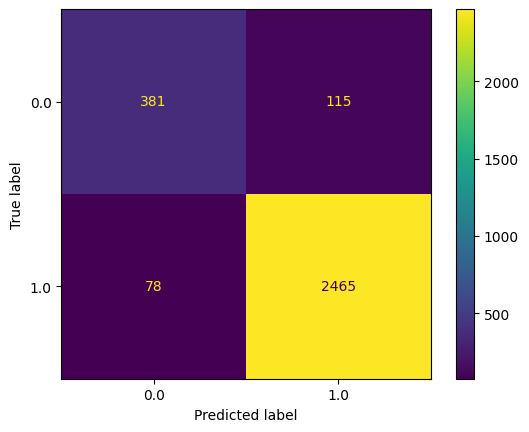

In [ ]:
y_pred = model.predict(X_test)
print('Accuracy ',accuracy_score(y_test, y_pred))
print('Precision ',precision_score(y_test, y_pred))
print('Recall ',recall_score(y_test, y_pred))
print('Confusion matrix ', confusion_matrix(y_test, y_pred))
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, y_pred),display_labels=model.classes_)
disp.plot()
plt.show()

In [ ]:
data = [{'Customer_Age':68, 'Gender':'F', 'Dependent_count':5, 'Education_Level':'Graduate',
 'Marital_Status':'Single', 'Income_Category':'Less than $40K', 'Card_Category':'Blue',
 'Months_on_book':44, 'Total_Relationship_Count':6, 'Months_Inactive_12_mon':1,
 'Contacts_Count_12_mon':2, 'Credit_Limit':8700,'Total_Revolving_Bal':800, 'Avg_Open_To_Buy':7392,
 'Total_Amt_Chng_Q4_Q1':1.541,'Total_Trans_Amt':1200,'Total_Trans_Ct':33,'Total_Ct_Chng_Q4_Q1':3.714,
 'Avg_Utilization_Ratio':0.10},
        {'Customer_Age':50, 'Gender':'M', 'Dependent_count':2, 'Education_Level':'Graduate',
 'Marital_Status':'Single', 'Income_Category':'$40K - $60K', 'Card_Category':'Blue',
 'Months_on_book':38, 'Total_Relationship_Count':3, 'Months_Inactive_12_mon':2,
 'Contacts_Count_12_mon':0, 'Credit_Limit':8077.0,'Total_Revolving_Bal':1965, 'Avg_Open_To_Buy':6112.0,
 'Total_Amt_Chng_Q4_Q1':0.637,'Total_Trans_Amt':1329,'Total_Trans_Ct':26,'Total_Ct_Chng_Q4_Q1':0.444,
 'Avg_Utilization_Ratio':0.243}]

df_input = pd.DataFrame(data)
#categorical encoding
df_X = df.drop(['CLIENTNUM', 'Attrition_Flag'],axis=1)
cats = df_X.select_dtypes(include=['object', 'bool']).columns
cat_features = list(cats.values)
for i in cat_features:
 le.fit(df_input[i])
 df_input[i] = le.transform(df_input[i])

#scaling
df_input= scaler.transform(df_input.astype(float).values)
result= model.predict(df_input)

for i in result:
 int_result = int(i)
 if (int_result == 0):
  decision = 'Existing Customer'
 elif (int_result==1):
  decision = 'Attrited Customer'
 else:
  decison = 'Not defined'
print('Result prediction is ', decision)

Result prediction is  Attrited Customer


In [ ]:
df_input

array([[ 2.69329634e+00, -9.46143311e-01,  2.08111844e+00,
        -1.68389487e+00, -1.97846227e+00, -1.23078045e+00,
        -2.55911655e-01,  1.00082113e+00,  1.41213614e+00,
        -1.32245379e+00, -4.09541072e-01,  9.83216719e-03,
        -4.44011649e-01, -6.39776613e-03,  3.62111505e+00,
        -9.40555602e-01, -1.35950899e+00,  1.26325766e+01,
        -6.32215193e-01],
       [ 4.59304076e-01,  1.05692234e+00, -2.54373565e-01,
        -1.68389487e+00, -1.97846227e+00, -1.89575277e+00,
        -2.55911655e-01,  2.55867580e-01, -5.14072268e-01,
        -3.37526559e-01, -2.22835505e+00, -5.91736804e-02,
         9.86864872e-01, -1.48262862e-01, -5.70385493e-01,
        -9.03179036e-01, -1.65490765e+00, -1.12681489e+00,
        -1.10932261e-01]])

In [ ]:
cat_features

['Gender',
 'Education_Level',
 'Marital_Status',
 'Income_Category',
 'Card_Category']

In [ ]:
result

array([1., 1.])

In [ ]:
import pandas as pd
df = pd.read_csv('https://raw.githubusercontent.com/ganjar87/data_science_practice/main/kc_house_data.csv', delimiter=',')
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [ ]:
df.isnull().sum()

,0
id,0
date,0
price,0
bedrooms,0
bathrooms,0
sqft_living,0
sqft_lot,0
floors,0
waterfront,0
view,0


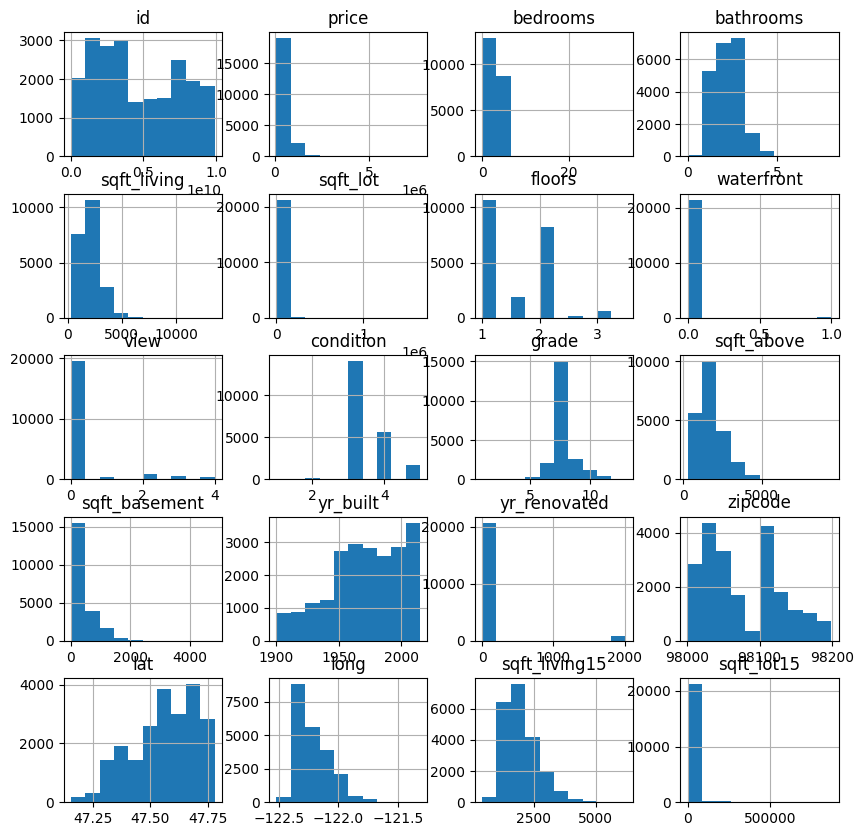

In [ ]:
df.hist(figsize=(10,10))
plt.show()

In [ ]:
df_X = df.drop(['id','date','price'],axis=1)
df_y = df[['price']]
cats = df_X.select_dtypes(include=['object', 'bool']).columns
print(cats)

Index([], dtype='object')


In [ ]:
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
import numpy as np

df_X = df.drop(['id', 'date','price'], axis=1)
df_y = df['price']

X = df_X.astype(float).values
y = df_y.astype(float).values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
reg = MLPRegressor()
reg.fit(X_train, y_train)

print('coef of determination training ',reg.score(X_train, y_train))
print('coef of determination testing ',reg.score(X_test, y_test))

print('prediction')
y_pred = reg.predict(X_test)
print(y_pred[:10])
print('real value')
print(y_test[0:10])

coef of determination training  0.5780212967988323
coef of determination testing  0.56088302793068
prediction
[ 503841.78877548  741866.76851274 1120249.95674458 1409402.10370721
  625779.55512317  394208.18648112  635025.06456526  522440.80737033
  494908.02268939  377266.12193609]
real value
[ 365000.  865000. 1038000. 1490000.  711000.  211000.  790000.  680000.
  384500.  605000.]


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

mse = mean_squared_error(y_test,y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test,y_pred)

print('rmse : ', rmse)
print('r2 :', r2)

rmse :  251781.24279345028
r2 : 0.56088302793068


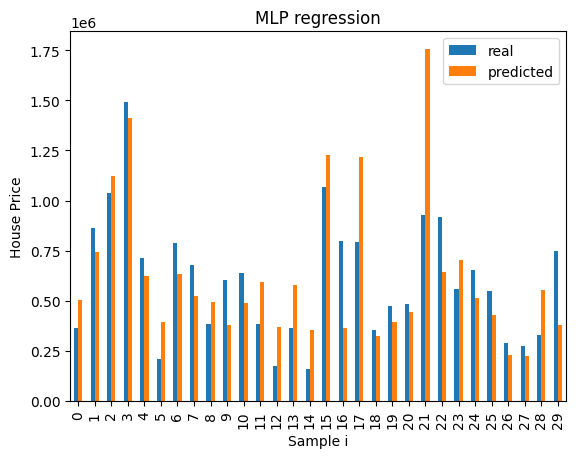

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

data1 = pd.DataFrame(y_test[:30], columns = ['real'])
data2 = pd.DataFrame(y_pred[:30], columns = ['predicted'])
df_new = pd.concat([data1, data2], axis=1)
df_new.plot(kind='bar')

plt.title("MLP regression")
plt.xlabel('Sample i')
plt.ylabel('House Price')

plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Load Dataset dari URL
url_cls = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
names = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
df_cls = pd.read_csv(url_cls, names=names)

print("=== DATASET KLASIFIKASI (PIMA DIABETES) ===")
display(df_cls.head())

=== DATASET KLASIFIKASI (PIMA DIABETES) ===


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
# Pisahkan Fitur dan Target
X = df_cls.drop('Outcome', axis=1)
y = df_cls['Outcome']

# Split Data (70% Train, 30% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Scaling (Standarisasi) - Wajib untuk Neural Network agar cepat konvergen
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Preprocessing selesai. Data siap dilatih.")

Preprocessing selesai. Data siap dilatih.


In [ ]:
# Membangun Model
# Hidden layer: 2 layer, masing-masing 16 dan 8 neuron
mlp_clf = MLPClassifier(hidden_layer_sizes=(16, 8),
                        max_iter=1000,
                        random_state=42,
                        activation='relu',
                        solver='adam')

# Melatih Model
mlp_clf.fit(X_train_scaled, y_train)
print("Training selesai.")

Training selesai.


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


=== PERFORMA MODEL KLASIFIKASI ===
Akurasi: 0.7229437229437229

Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.79      0.79       151
           1       0.60      0.59      0.59        80

    accuracy                           0.72       231
   macro avg       0.69      0.69      0.69       231
weighted avg       0.72      0.72      0.72       231



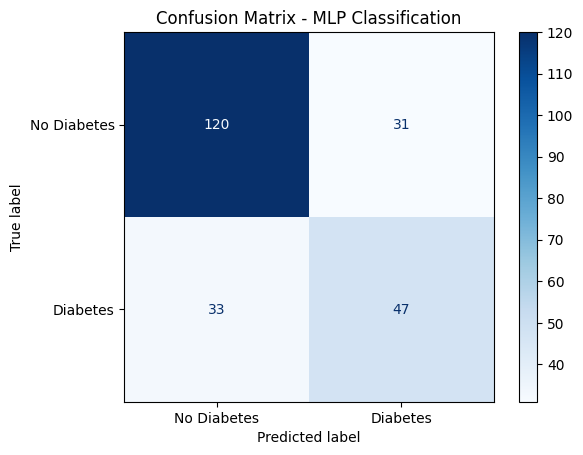

In [ ]:
# Prediksi
y_pred_cls = mlp_clf.predict(X_test_scaled)

# Tampilkan Metrik
print("=== PERFORMA MODEL KLASIFIKASI ===")
print("Akurasi:", accuracy_score(y_test, y_pred_cls))
print("\nClassification Report:\n", classification_report(y_test, y_pred_cls))

# Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_pred_cls)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Diabetes', 'Diabetes'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix - MLP Classification")
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Load Dataset
url_reg = "https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv"
df_reg = pd.read_csv(url_reg)

print("=== DATASET REGRESI (BOSTON HOUSING) ===")
display(df_reg.head())

=== DATASET REGRESI (BOSTON HOUSING) ===


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [ ]:
# Target adalah 'medv' (Median value of owner-occupied homes)
X_reg = df_reg.drop('medv', axis=1)
y_reg = df_reg['medv']

# Split Data
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X_reg, y_reg, test_size=0.3, random_state=42)

# Scaling
scaler_reg = StandardScaler()
X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_test_reg_scaled = scaler_reg.transform(X_test_reg)

print("Preprocessing Regresi selesai.")

Preprocessing Regresi selesai.


In [ ]:
# Membangun Model Regresi
# Hidden layer: 3 layer (64, 32, 16 neuron)
mlp_reg = MLPRegressor(hidden_layer_sizes=(64, 32, 16),
                       max_iter=2000,
                       random_state=42,
                       activation='relu',
                       solver='adam',
                       learning_rate_init=0.01)

# Melatih Model
mlp_reg.fit(X_train_reg_scaled, y_train_reg)
print("Training Regresi selesai.")

Training Regresi selesai.


=== PERFORMA MODEL REGRESI ===
RMSE (Root Mean Squared Error): 3.6645
R2 Score (Kebaikan Model): 0.8198


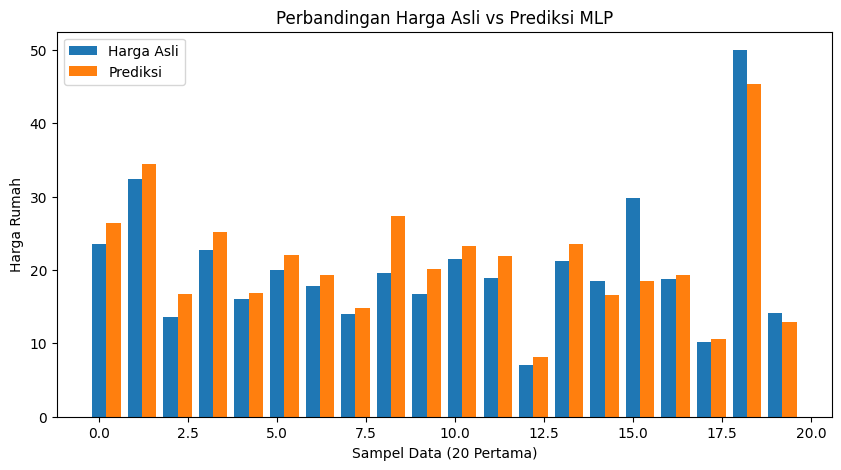

In [ ]:
# Prediksi
y_pred_reg = mlp_reg.predict(X_test_reg_scaled)

# Hitung Metrik Error
mse = mean_squared_error(y_test_reg, y_pred_reg)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_reg, y_pred_reg)

print("=== PERFORMA MODEL REGRESI ===")
print(f"RMSE (Root Mean Squared Error): {rmse:.4f}")
print(f"R2 Score (Kebaikan Model): {r2:.4f}")

# Visualisasi Bar Chart (Perbandingan 20 data pertama)
plt.figure(figsize=(10, 5))
plt.bar(np.arange(20), y_test_reg[:20], width=0.4, label='Harga Asli', align='center')
plt.bar(np.arange(20) + 0.4, y_pred_reg[:20], width=0.4, label='Prediksi', align='center')
plt.xlabel('Sampel Data (20 Pertama)')
plt.ylabel('Harga Rumah')
plt.title('Perbandingan Harga Asli vs Prediksi MLP')
plt.legend()
plt.show()